**Setup**

Import the required libraries and load the chatbot conversation dataset.

* Dataset: bitext/customer-support-llm-chatbot-training-dataset (Modified)
* Original: https://huggingface.co/datasets/bitext/customer-support-llm-chatbot-training-dataset

MODIFICATIONS (Educational):
- Added synthetic PII columns and injected PII into text
- Introduced data quality issues
- Purpose: Simulate realistic data preprocessing challenges

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Load the chatbot conversation dataset
df = pd.read_csv('./data/customer_support_clean.csv')

**Example**

You'll work with production conversation logs from your AI chatbot. Each row represents one conversation with metrics like response time, cost, and quality indicators. Explore a sample conversation:

In [2]:
print("=== Dataset Overview ===")
sample = df.iloc[100]
print(f"Model used: {sample['model_used']}")
print(f"Latency: {sample['latency_seconds']:.2f}s")
print(f"Tokens used: {sample['tokens_used']}")
print(f"Cost: ${sample['cost']:.4f}")
print(f"Resolved: {sample['resolved']}")
print(f"CSAT: {sample['csat_score']}/5")
print(f"Hallucinated: {sample['hallucinated']}")
print(f"Week: {sample['week_number']}")
print(f"Columns: {', '.join(df.columns)}")

=== Dataset Overview ===
Model used: gpt-4
Latency: 2.78s
Tokens used: 194
Cost: $0.0058
Resolved: True
CSAT: 3.1/5
Hallucinated: False
Week: 5
Columns: customer_id_hashed, customer_type, zipcode, week_number, flags, instruction, response, category, intent, model_tier, model_used, tokens_used, cost, latency_seconds, conversation_turns, resolved, escalated_to_human, csat_score, hallucinated, error_occurred


Your chatbot launched with a 73% resolution rate in Week 1. You need to track whether performance is staying stable or degrading over the 5 weeks. A >5% drop from baseline signals a problem that needs investigation.

1. Calculate the resolution rate for each week (Week 1-5)
2. Set Week 1 as the baseline (starting point)
3. Calculate the percentage change from baseline for each subsequent week
4. Flag weeks where the resolution rate dropped >5% from baseline (warning) or >10% (critical)

In [4]:
# Calculate weekly metrics
weekly_metrics = df.groupby('week_number').agg(
    resolution_rate=pd.NamedAgg(column='resolved', aggfunc='mean'),
    count=pd.NamedAgg(column='resolved', aggfunc='count')
)

# Establish baseline (Week 1)
baseline_resolution =  weekly_metrics.loc[df['week_number'] == 1, 'resolution_rate'].values[0]

# Calculate percentage change from baseline
weekly_metrics['resolution_change_pct'] = (
    (weekly_metrics['resolution_rate'] - baseline_resolution) # type: ignore
    / baseline_resolution * 100
) 

print("=== Performance Drift Detection ===")
print(f"\nBaseline (Week 1):")
print(f"  Resolution rate: {baseline_resolution:.1%}")

print(f"\n{'='*80}")
print(f"Weekly Performance Tracking:")
print(f"{'='*80}")

drift_detected = False

for week in range(1, 5):
    metrics = weekly_metrics.loc[week]
    
    print(f"\nWEEK {week}:")
    # Resolution rate status
    if metrics['resolution_change_pct'] <= -10: # type: ignore
        status = "[CRITICAL]"
    elif metrics['resolution_change_pct'] <= -5: # type: ignore
        status = "[WARNING]"
    else:
        status = "[OK]"
    
    print(f"  {status} Resolution: {metrics['resolution_rate']:.1%} ({metrics['resolution_change_pct']:+.1f}% from baseline)")

=== Performance Drift Detection ===

Baseline (Week 1):
  Resolution rate: 73.2%

Weekly Performance Tracking:

WEEK 1:
  [OK] Resolution: 73.2% (+0.0% from baseline)

WEEK 2:
  [OK] Resolution: 73.3% (+0.2% from baseline)

WEEK 3:
  [OK] Resolution: 72.5% (-0.9% from baseline)

WEEK 4:
  [OK] Resolution: 74.0% (+1.1% from baseline)


#### Checkpoint 2/3
Now it's time to check if there are any significant changes to the input data. Are the categories of questions customers ask changing over time? 

1. Calculate the distribution of conversation categories (billing, technical, account) in Week 1 (baseline)
2. Calculate the distribution of conversation categories in Week 5 (current)
3. Run a chi-square test using `stats.chi2_contingency()` to determine if the distribution changed significantly
   - Create a contingency table with category counts for Week 1 and Week 5
   - If p-value < 0.05, the distribution shift is statistically significant

**Why this matters:** If your AI was trained on 60% billing questions but now 60% are account questions, it's like asking a math expert to suddenly teach history.

Don't forget to run the cell and save the notebook before selecting `Test Work`!

In [7]:
print("=== Data Drift Detection: Conversation Topics ===")
print("\nAnalyzing distribution shift from Week 1 to Week 5...\n")

# Get baseline (Week 1) distribution
week1_data =  df[df['week_number'] == 1]
week1_distribution = week1_data['category'].value_counts()
week1_counts = week1_distribution

# Get current (Week 5) distribution
week5_data =  df[df['week_number'] == 5]
week5_distribution = week5_data['category'].value_counts()
week5_counts = week5_distribution

print("BASELINE (Week 1):")
for category, pct in week1_distribution.items():
    print(f"  {category}: {pct:.1%} ({week1_counts[category]} conversations)")

print(f"\nCURRENT (Week 5):")
for category, pct in week5_distribution.items():
    print(f"  {category}: {pct:.1%} ({week5_counts[category]} conversations)")


# Statistical significance test
print(f"\n{'='*80}")
print("Statistical Significance Test (Chi-Square):")
print(f"{'='*80}")

# Create contingency table
all_categories = sorted(set(week1_counts.index) | set(week5_counts.index))
contingency_table = []
contingency_table.append([week1_counts.get(cat, 0) for cat in all_categories])
contingency_table.append([week5_counts.get(cat, 0) for cat in all_categories])

print(f"\nContingency Table:")
print(f"{'Category':<15} {'Week 1':<10} {'Week 5':<10}")
print("-" * 40)
for i, cat in enumerate(all_categories):
    print(f"{cat:<15} {contingency_table[0][i]:<10} {contingency_table[1][i]:<10}")

# Run chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)

print(f"\nChi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of freedom: {dof}")


=== Data Drift Detection: Conversation Topics ===

Analyzing distribution shift from Week 1 to Week 5...

BASELINE (Week 1):
  ACCOUNT: 102600.0% (1026 conversations)
  ORDER: 66100.0% (661 conversations)
  REFUND: 52000.0% (520 conversations)
  CONTACT: 34100.0% (341 conversations)
  PAYMENT: 33600.0% (336 conversations)
  INVOICE: 32300.0% (323 conversations)
  DELIVERY: 31900.0% (319 conversations)
  SHIPPING: 30900.0% (309 conversations)
  FEEDBACK: 29900.0% (299 conversations)
  CANCEL: 17500.0% (175 conversations)
  SUBSCRIPTION: 17000.0% (170 conversations)

CURRENT (Week 5):
  ACCOUNT: 77000.0% (770 conversations)
  ORDER: 55400.0% (554 conversations)
  REFUND: 43500.0% (435 conversations)
  SHIPPING: 29400.0% (294 conversations)
  PAYMENT: 29100.0% (291 conversations)
  FEEDBACK: 28000.0% (280 conversations)
  INVOICE: 27100.0% (271 conversations)
  DELIVERY: 27000.0% (270 conversations)
  CONTACT: 24000.0% (240 conversations)
  SUBSCRIPTION: 13000.0% (130 conversations)
  CAN

So far, resolution rates look stable over time.  But before you celebrate, you are asked to explore if there is any drift in resolution rates by _customer type_.  

1. Calculate the resolution rate by customer type for Week 1 (baseline) and Week 5 (current)
2. Calculate the change in resolution rate for each customer type from Week 1 to Week 5
3. Create a bar chart visualization comparing Week 1 vs Week 5 performance

=== Subgroup Drift Analysis ===

Analyzing resolution rate by customer segments 


Week 1 (Baseline) by Customer Type:
  enterprise: 73.5% (1124.0 conversations)
  new: 72.0% (1107.0 conversations)
  premium: 72.3% (1127.0 conversations)
  returning: 74.8% (1121.0 conversations)

Week 5 (Current) by Customer Type:
  enterprise: 73.5% (897.0 conversations)
  new: 73.5% (906.0 conversations)
  premium: 73.0% (933.0 conversations)
  returning: 70.2% (928.0 conversations)

Performance Changes (Week 1 → Week 5):
  [OK] enterprise: -0.0% (-0.0 points)
  [OK] new: +2.1% (+1.5 points)
  [OK] premium: +0.9% (+0.7 points)
  [WARNING] returning: -6.3% (-4.7 points)


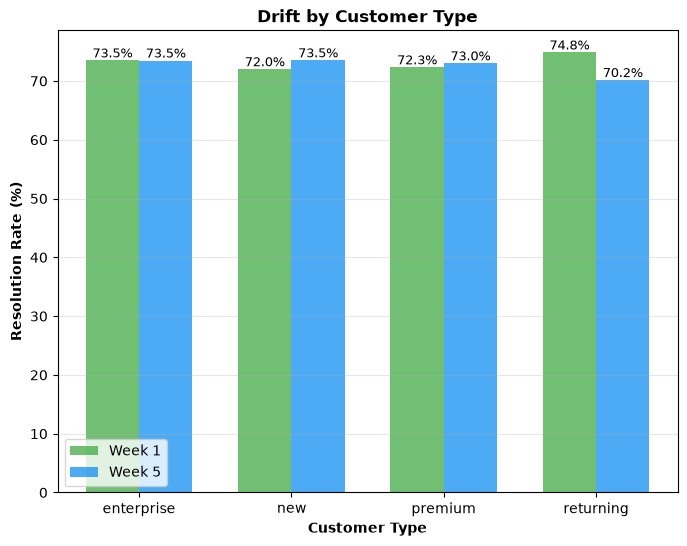

In [8]:
print("=== Subgroup Drift Analysis ===")
print("\nAnalyzing resolution rate by customer segments \n")

# Week 1 baseline by customer type
week1_by_type =  df[df['week_number'] == 1].groupby('customer_type').agg(
    resolution_rate=('resolved', 'mean'),
    count=('resolved', 'size')
)

# Week 5 current by customer type
week5_by_type =  df[df['week_number'] == 5].groupby('customer_type').agg(
    resolution_rate=('resolved', 'mean'),
    count=('resolved', 'size')
)

print("\nWeek 1 (Baseline) by Customer Type:")
for ctype, row in week1_by_type.iterrows():
    print(f"  {ctype}: {row['resolution_rate']:.1%} ({row['count']} conversations)")

print("\nWeek 5 (Current) by Customer Type:")
for ctype, row in week5_by_type.iterrows():
    print(f"  {ctype}: {row['resolution_rate']:.1%} ({row['count']} conversations)")

# Calculate changes
print("\nPerformance Changes (Week 1 → Week 5):")
type_changes = {}
for ctype in week1_by_type.index:
    week1_rate =  week1_by_type.loc[ctype, 'resolution_rate'] * 100
    week5_rate =  week5_by_type.loc[ctype, 'resolution_rate'] * 100
    change_pct =  (week5_rate - week1_rate) / week1_rate * 100
    change_points =  week5_rate - week1_rate
    type_changes[ctype] =  change_pct
    
    status = "[WARNING]" if change_pct < -5 else "[OK]"
    print(f"  {status} {ctype}: {change_pct:+.1f}% ({change_points:+.1f} points)")


# === VISUALIZATIONS ===

# Figure 1: Customer Type Comparison
fig, ax1 = plt.subplots(1, 1, figsize=(8, 6))

# Customer type bar chart
customer_types = list(week1_by_type.index)
x = np.arange(len(customer_types))
width = 0.35

week1_rates = [week1_by_type.loc[ct, 'resolution_rate'] * 100 for ct in customer_types]
week5_rates = [week5_by_type.loc[ct, 'resolution_rate'] * 100 for ct in customer_types]

bars1 = ax1.bar(x - width/2,  week1_rates,  width, label='Week 1', color='#4CAF50', alpha=0.8)
bars2 = ax1.bar(x + width/2, week5_rates, width, label='Week 5', color='#2196F3', alpha=0.8)

ax1.set_xlabel('Customer Type', fontweight='bold')
ax1.set_ylabel('Resolution Rate (%)', fontweight='bold')
ax1.set_title('Drift by Customer Type', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(customer_types)
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%', ha='center', va='bottom', fontsize=9)
